# African SLM Tool Calling Hackathon: starter notebook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aims-ai-research-foundations/airf-slm-tool-calling-hackathon/blob/main/starter_notebook.ipynb)

Three approaches with **Gemma 3 270M**, each scored by exact-match accuracy:

1. **Zero-shot prompting**: no training.
2. **Fine-tuning** on 1,000 training examples.
3. **More training data**: the same fine-tuning on 3,000 examples.

Runtime: about 20 minutes on a Colab T4 GPU (*Runtime → Change runtime type → T4 GPU*).

# Install Libraries

In [1]:
import importlib.util
import subprocess
import sys

# Ensure torchao is installed and upgraded to a version > 0.16.0
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", "torchao"])

missing = [package for package in ("peft", "accelerate") if importlib.util.find_spec(package) is None]
if missing:  # Colab already has torch and transformers
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("installed:", missing or "nothing needed (torchao upgraded)")

installed: nothing needed (torchao upgraded)


# Environment and Imports

In [2]:
import json
import math
import os
import random
import re
import time
import urllib.request
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from peft import LoraConfig, get_peft_model
from transformers import AutoModelForCausalLM, AutoTokenizer

SEED = 0
random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE, DTYPE = "cuda", torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float32
elif torch.backends.mps.is_available():
    DEVICE, DTYPE = "mps", torch.bfloat16
else:
    DEVICE, DTYPE = "cpu", torch.float32
print("device:", DEVICE)

# Charts: one fixed colour per approach.
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3de", "axes.axisbelow": True, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False})

W1123 12:37:27.422000 15122 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1123 12:37:27.521000 15122 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


device: cuda


Gemma needs a Hugging Face token from an account that has accepted the
[Gemma licence](https://huggingface.co/google/gemma-3-270m-it). On Colab, add it to *Secrets* as `HF_TOKEN`.

In [3]:
try:
    from google.colab import userdata
    from huggingface_hub import login

    login(userdata.get("HF_TOKEN"))
except ImportError:  # not on Colab: use `huggingface-cli login` or the HF_TOKEN variable
    pass

The data is downloaded from the [hackathon repository](https://github.com/aims-ai-research-foundations/airf-slm-tool-calling-hackathon) into `data/`.

In [4]:
import json
from pathlib import Path
import urllib.request
import zipfile
from google.colab import drive

# 1. Monter Google Drive et extraire l'archive de la Phase 2
drive.mount("/content/drive")

ZIP_PATH = (
    "/content/drive/MyDrive/Gemma4B_Hackathon/submissions/public_data_final.zip"
)
REPO = "https://raw.githubusercontent.com/aims-ai-research-foundations/airf-slm-tool-calling-hackathon/main/data"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
  zf.extractall(DATA_DIR)
  print("Fichiers extraits depuis Drive :", zf.namelist())

# 2. Télécharger uniquement train.jsonl depuis GitHub (tools.json et test.jsonl viennent du ZIP final)
train_dest = DATA_DIR / "train.jsonl"
if not train_dest.exists():
  urllib.request.urlretrieve(f"{REPO}/train.jsonl", train_dest)


# 3. Fonctions utilitaires
def read_jsonl(path: Path) -> list[dict]:
  return [
      json.loads(line)
      for line in path.read_text(encoding="utf-8").splitlines()
      if line.strip()
  ]


def answer_of(row: dict):
  """A training row's answer: its tool_calls, or its tool and parameters."""
  return (
      row["tool_calls"]
      if "tool_calls" in row
      else {"tool": row["tool"], "parameters": row["parameters"]}
  )


def calls_of(answer) -> list[dict]:
  return answer if isinstance(answer, list) else [answer]


# 4. Charger les données de Phase 2
tools = {
    tool["name"]: tool
    for tool in json.loads((DATA_DIR / "tools.json").read_text(encoding="utf-8"))
}
train = [
    dict(row, answer=answer_of(row))
    for row in read_jsonl(DATA_DIR / "train.jsonl")
]
test = read_jsonl(DATA_DIR / "test.jsonl")

print(f"\n{len(tools)} tools · {len(train):,} train · {len(test):,} test")
print("Premier ID test :", test[0].get("id"), "| Dernier ID test :", test[-1].get("id"))
print("\n--- README_final_phase.md ---")
print((DATA_DIR / "README_final_phase.md").read_text(encoding="utf-8"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fichiers extraits depuis Drive : ['test.jsonl', 'tools.json', 'README_final_phase.md']

10 tools · 15,000 train · 4,000 test
Premier ID test : test-00001 | Dernier ID test : test-04000

--- README_final_phase.md ---
# Final phase: test.jsonl

`test.jsonl` has 4,000 requests (fields: id, request, tools), with the answers hidden. The tools are the same as in
`tools.json`.

Make one prediction for every id (test-00001 to test-04000) in the same format as the development phase: a single
`predictions.json` object keyed by request id. Zip it and submit it under My Submissions in the Final phase.

The final ranking uses exact-match accuracy on this test set. You can submit up to 2 times a day (5 in total).



# Exploratory Data Analysis

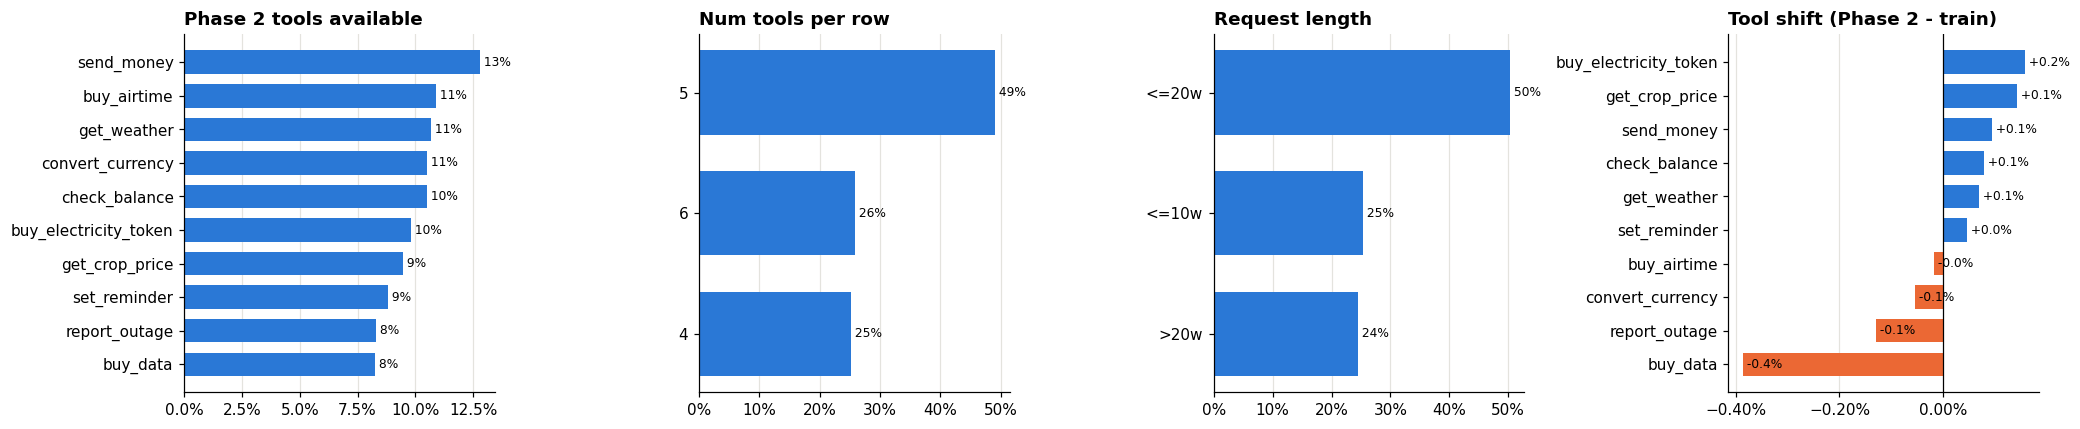

In [5]:
from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd

c_blue = BLUE if "BLUE" in globals() else "#2563EB"
c_orange = ORANGE if "ORANGE" in globals() else "#EA580C"

# Phase 2 test set (4,000 rows: id, request, tools)
tool_counts = Counter(t for ex in test for t in ex["tools"])
n_tools_counts = Counter(len(ex["tools"]) for ex in test)
len_buckets = Counter(
    "<=10w"
    if len(ex["request"].split()) <= 10
    else ("<=20w" if len(ex["request"].split()) <= 20 else ">20w")
    for ex in test
)

# Shift vs train if `train` is loaded, otherwise candidate pool size
if "train" in globals() and len(train) > 0:
  tr_counts = Counter(t for ex in train for t in ex["tools"])
  tr_tot = sum(tr_counts.values())
  te_tot = sum(tool_counts.values())
  fourth_panel = (
      "Tool shift (Phase 2 - train)",
      pd.Series({
          t: (tool_counts[t] / te_tot) - (tr_counts[t] / tr_tot)
          for t in tool_counts
      }).sort_values(),
  )
else:
  pool_counts = Counter(
      ("multi_cand" if len(ex["tools"]) > 3 else "few_cand") for ex in test
  )
  fourth_panel = (
      "Candidate pool size",
      (pd.Series(pool_counts) / sum(pool_counts.values())).sort_values(),
  )

panels = [
    (
        "Phase 2 tools available",
        (pd.Series(tool_counts) / sum(tool_counts.values())).sort_values(),
    ),
    (
        "Num tools per row",
        (pd.Series(n_tools_counts) / sum(n_tools_counts.values())).sort_values(),
    ),
    (
        "Request length",
        (pd.Series(len_buckets) / sum(len_buckets.values())).sort_values(),
    ),
    fourth_panel,
]

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, (title, values) in zip(axes, panels):
  is_shift = "shift" in title.lower()
  colors = (
      [c_orange if v < 0 else c_blue for v in values.values]
      if is_shift
      else [c_blue] * len(values)
  )
  ax.barh(
      [str(k) for k in values.index], values.values, color=colors, height=0.7
  )
  for y, v in enumerate(values.values):
    ax.text(
        v, y, f" {v:+.1%}" if is_shift else f" {v:.0%}", va="center", fontsize=8
    )
  if is_shift:
    ax.axvline(0, color="black", linewidth=0.8)
  ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
  ax.grid(axis="y", visible=False)
  ax.set_title(title)

plt.tight_layout()
plt.show()

In [6]:
for category in ("single", "missing_info", "multiple"):
    ex = next(ex for ex in train if ex["meta"]["category"] == category)
    print(f"[{category}] {ex['request']}\n  -> {json.dumps(ex['answer'], ensure_ascii=False)}\n")

[single] Quick one: my cousin abroad sent me two hundred Ghana cedis. How much is that in EUR? Cheers.
  -> {"tool": "convert_currency", "parameters": {"amount": 200, "from_currency": "GHS", "to_currency": "EUR"}}

[missing_info] 2k Rwandan francs airtime for +250732453875
  -> {"tool": "buy_airtime", "parameters": {"phone": "+250732453875", "amount": 2000, "network": null}}

[multiple] don't let me forget to pick up the kids from school on tuesday at 7:15am. also, what is kes 20k worth in ugandan shillings?
  -> [{"tool": "set_reminder", "parameters": {"task": "pick up the kids from school", "date": "tuesday", "time": "07:15"}}, {"tool": "convert_currency", "parameters": {"amount": 20000, "from_currency": "KES", "to_currency": "UGX"}}]



In [7]:
print("VARIABLES DISPONIBLES :")

for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "train", "data", "dataset", "tool", "valid", "dev", "test"
    ]):
        try:
            obj = globals()[name]
            print(f"{name}: {type(obj).__name__}", end="")
            if hasattr(obj, "__len__"):
                print(f" | Taille: {len(obj)}")
            else:
                print()
        except:
            pass


VARIABLES DISPONIBLES :
DATA_DIR: PosixPath
DEVICE: str | Taille: 4
n_tools_counts: Counter | Taille: 3
test: list | Taille: 4000
tool_counts: Counter | Taille: 10
tools: dict | Taille: 10
train: list | Taille: 15000
train_dest: PosixPath
userdata: module


In [8]:
import random
import copy
from collections import Counter

random.seed(42)

# Reconstruire les données d'entraînement
train_pool = copy.deepcopy(train)

# Calculer la répartition des outils
per_tool = Counter(t for ex in train_pool for t in ex["tools"])

# Vérifier la structure
print("Nombre d'exemples :", len(train_pool))
print("\nPremier exemple :")
print(train_pool[0])

print("\nRépartition des outils :")
print(per_tool)

print("\nDéfinitions des outils :")
print(tools)

Nombre d'exemples : 15000

Premier exemple :
{'id': 'train-00001', 'request': "don't let me forget to pick up the kids from school on tuesday at 7:15am. also, what is kes 20k worth in ugandan shillings?", 'tools': ['get_weather', 'buy_electricity_token', 'buy_data', 'set_reminder', 'convert_currency', 'send_money'], 'tool_calls': [{'tool': 'set_reminder', 'parameters': {'task': 'pick up the kids from school', 'date': 'tuesday', 'time': '07:15'}}, {'tool': 'convert_currency', 'parameters': {'amount': 20000, 'from_currency': 'KES', 'to_currency': 'UGX'}}], 'meta': {'country': 'KE', 'city': 'Mombasa', 'style': 'chat', 'category': 'multiple', 'kind': 'different_tools', 'n_calls': 2, 'null_params': []}, 'answer': [{'tool': 'set_reminder', 'parameters': {'task': 'pick up the kids from school', 'date': 'tuesday', 'time': '07:15'}}, {'tool': 'convert_currency', 'parameters': {'amount': 20000, 'from_currency': 'KES', 'to_currency': 'UGX'}}]}

Répartition des outils :
Counter({'send_money': 9535

In [9]:
import copy
import random
from collections import Counter

random.seed(42)

# ============================================================
# 1. CONFIGURATION
# ============================================================

TARGET_SIZE = 30000
N_SYNTHETIC = TARGET_SIZE - len(train)

prefixes = [
    "Please help me with this request: ",
    "Can you take care of this for me? ",
    "I need your assistance with this: ",
    "Could you please process this request? ",
    "Here is what I would like you to do: ",
    "Please handle the following: ",
    "I have a request: ",
    "Can you help me with the following? ",
    "I would like you to do this: ",
    "Kindly assist me with this: ",
    "Would you please help me with this? "
]

suffixes = [
    "", " Please.", " Thanks.",
    " Thank you.", " I would appreciate your help."
]

# ============================================================
# 2. GENERATION
# ============================================================

synthetic_examples = []

for i in range(N_SYNTHETIC):

    original = copy.deepcopy(train[i % len(train)])
    example = copy.deepcopy(original)

    request = original.get("request")

    if not isinstance(request, str) or not request.strip():
        continue

    example["request"] = (
        random.choice(prefixes)
        + request.strip()
        + random.choice(suffixes)
    )

    # Identifiant synthétique unique
    example["id"] = f"synthetic-{i+1:05d}"

    # Conserver exactement les clés et les labels d'origine
    for key in original:
        if key != "id" and key != "request":
            example[key] = copy.deepcopy(original[key])

    synthetic_examples.append(example)

# ============================================================
# 3. DATASET FINAL
# ============================================================

augmented_train_pool = (
    copy.deepcopy(train) + synthetic_examples
)

random.shuffle(augmented_train_pool)

# ============================================================
# 4. CONTROLES
# ============================================================

print("=" * 55)
print("AUGMENTATION TERMINEE")
print("=" * 55)

print("Originaux :", len(train))
print("Synthétiques :", len(synthetic_examples))
print("Total :", len(augmented_train_pool))

assert len(augmented_train_pool) == TARGET_SIZE

# Vérification de la conservation des réponses
for i in range(min(100, len(synthetic_examples))):
    source = train[i]
    generated = synthetic_examples[i]

    assert generated["answer"] == source["answer"]

print("\n100 premières réponses vérifiées.")

print("\nRépartition des catégories :")
print(Counter(
    x.get("meta", {}).get("category", "unknown")
    for x in augmented_train_pool
))

print("\nDataset prêt.")

AUGMENTATION TERMINEE
Originaux : 15000
Synthétiques : 15000
Total : 30000

100 premières réponses vérifiées.

Répartition des catégories :
Counter({'single': 18000, 'missing_info': 6000, 'multiple': 6000})

Dataset prêt.


- 60% of requests need one call with every value given, 20% leave a value out (`null`), 20% need several calls.
- Tools and countries are evenly spread.
- The value most often missing is the currency: it is only given when the request writes it ("5k" alone has none).

# Gemma 270M Zero-Shot Prompting

The prompt is a one-line instruction, a signature for each offered tool, and the request. The model answers with
a JSON **list** of calls (a list of one call scores the same as the call itself). We score on **300 training
examples held out for validation**, 100 per category.

In [10]:
MODEL_NAME = "google/gemma-3-4B-it"
INSTRUCTION = "Reply with a JSON list of the tool calls for the request, with null for values not given.\nTools:\n"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = "left"


def build_prompt(example: dict) -> str:
    signatures = [f"{name}({', '.join(f'{p}: {t}' for p, t in tools[name]['parameters'].items())})" for name in example["tools"]]
    messages = [{"role": "system", "content": INSTRUCTION + "\n".join(signatures)}, {"role": "user", "content": example["request"]}]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)


def target_text(answer) -> str:
    return json.dumps(calls_of(answer), ensure_ascii=False) + "<end_of_turn>"


by_category = defaultdict(list)
for ex in train:
    by_category[ex["meta"]["category"]].append(ex)
validation = [ex for group in by_category.values() for ex in random.Random(SEED).sample(group, 100)]
held = {ex["id"] for ex in validation}
train_pool = [ex for ex in train if ex["id"] not in held]

print(build_prompt(validation[0]) + target_text(validation[0]["answer"]))

<bos><start_of_turn>user
Reply with a JSON list of the tool calls for the request, with null for values not given.
Tools:
convert_currency(amount: number, from_currency: string, to_currency: string)
get_weather(location: string, date: string)
buy_airtime(phone: string, amount: number, network: string)
buy_electricity_token(meter_number: string, amount: number, currency: string)
send_money(recipient: string, amount: number, currency: string, provider: string)
report_outage(location: string)

Good afternoon. Check the forecast for Kasama on the 4th of Apr and buy a K500 electricity token for meter 43120234071. Thank you.<end_of_turn>
<start_of_turn>model
[{"tool": "get_weather", "parameters": {"location": "Kasama", "date": "4 April"}}, {"tool": "buy_electricity_token", "parameters": {"meter_number": "43120234071", "amount": 500, "currency": "ZMW"}}]<end_of_turn>


In [11]:
import gc
import time
import math
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import (
    AutoModelForCausalLM,
    BitsAndBytesConfig
)
from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training
)

COLORS = {
    "1. Zero-shot": MUTED,
    "2. Fine-tuned (1,000)": ORANGE,
    "3. Fine-tuned (3,000)": BLUE
}

def fine_tune(
    examples: list[dict],
    lr: float = 2e-4,
    batch_tokens: int = 1024
):
    """Gemma 3 1B - QLoRA 4 bits - GPU T4."""

    start = time.time()
    print("Chargement de Gemma 3 1B en QLoRA 4 bits...")

    # 1. Quantification 4 bits
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True
    )

    # 2. Chargement du modèle quantifié
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        quantization_config=bnb_config,
        device_map={"": 0},
        attn_implementation="eager"
    )

    # 3. Préparation QLoRA
    model.config.use_cache = False
    model = prepare_model_for_kbit_training(
        model,
        use_gradient_checkpointing=False
    )

    # 4. Adaptateurs LoRA
    lora_config = LoraConfig(
        task_type="CAUSAL_LM",
        r=16,
        lora_alpha=32,
        lora_dropout=0.05,
        target_modules="all-linear",
        bias="none"
    )

    model = get_peft_model(model, lora_config)
    model.print_trainable_parameters()

    print("\nPréparation des données...")

    # 5. Préparation des séquences
    rows = []
    for ex in examples:
        prompt = tokenizer(
            build_prompt(ex),
            add_special_tokens=False
        )["input_ids"]

        answer = tokenizer(
            target_text(ex["answer"]),
            add_special_tokens=False
        )["input_ids"]

        rows.append((
            prompt + answer,
            [-100] * len(prompt) + answer
        ))

    random.Random(SEED).shuffle(rows)
    rows.sort(key=lambda row: len(row[0]) // 32)

    # 6. Construction des lots
    batches = []
    batch = []
    current_tokens = 0

    for row in rows:
        row_tokens = len(row[0])
        if batch and current_tokens + row_tokens > batch_tokens:
            batches.append(batch)
            batch = []
            current_tokens = 0
        batch.append(row)
        current_tokens += row_tokens

    if batch:
        batches.append(batch)

    random.Random(SEED).shuffle(batches)

    # 7. Optimisation
    trainable_params = [
        p for p in model.parameters() if p.requires_grad
    ]

    optimizer = torch.optim.AdamW(
        trainable_params,
        lr=lr
    )

    schedule = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda s: min(1, (s + 1) / 10) *
        0.5 * (1 + math.cos(math.pi * s / len(batches)))
    )

    base = model.get_base_model()
    model.train()

    losses = []
    total_steps = len(batches)

    print(
        f"\nDébut : {len(examples):,} exemples | "
        f"{total_steps:,} étapes\n"
    )

    # 8. Entraînement avec progression
    progress = tqdm(
        enumerate(batches, 1),
        total=total_steps,
        desc="QLoRA Gemma 3 1B",
        unit="batch"
    )

    for step, batch in progress:
        width = max(len(ids) for ids, _ in batch)

        ids = torch.tensor(
            [
                [tokenizer.pad_token_id] * (width - len(i)) + i
                for i, _ in batch
            ],
            device="cuda"
        )

        labels = torch.tensor(
            [
                [-100] * (width - len(l)) + l
                for _, l in batch
            ],
            device="cuda"
        )

        mask = (ids != tokenizer.pad_token_id).long()

        hidden = base.model(
            input_ids=ids,
            attention_mask=mask,
            position_ids=(mask.cumsum(1) - 1).clamp(min=0)
        ).last_hidden_state

        targets = labels[:, 1:]
        keep = targets != -100

        logits = base.lm_head(
            hidden[:, :-1][keep]
        ).float()

        loss = torch.nn.functional.cross_entropy(
            logits,
            targets[keep]
        )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Loss invalide à l'étape {step}"
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            trainable_params,
            1.0
        )

        optimizer.step()
        schedule.step()
        optimizer.zero_grad(set_to_none=True)

        losses.append(loss.item())

        elapsed = (time.time() - start) / 60
        eta = (
            elapsed / step
        ) * (total_steps - step)

        avg_loss = np.mean(losses[-10:])

        progress.set_postfix({
            "Loss": f"{loss.item():.4f}",
            "Moyenne": f"{avg_loss:.4f}",
            "Temps": f"{elapsed:.1f} min",
            "ETA": f" {eta:.1f} min"
        })

        del hidden, logits, loss, ids, labels, mask

    # 9. Fin
    model.config.use_cache = True
    elapsed_min = (time.time() - start) / 60

    print("\nENTRAÎNEMENT TERMINÉ")
    print(f"Exemples : {len(examples):,}")
    print(f"Étapes : {total_steps:,}")
    print(f"Durée : {elapsed_min:.2f} minutes")
    print(f"Loss finale : {losses[-1]:.5f}")

    return model, losses

def plot(losses: dict):
    """The training loss of each fine-tuning run, and the exact match of every approach so far."""
    fig, (loss_ax, score_ax) = plt.subplots(
        1,
        2,
        figsize=(16, 4.5),
        gridspec_kw={"width_ratios": [1, 1.5]}
    )

    for name, values in losses.items():
        loss_ax.plot(
            pd.Series(values).rolling(10, min_periods=1).mean(),
            color=COLORS[name],
            linewidth=2,
            label=name
        )
    loss_ax.set(
        title="Training loss",
        xlabel="step",
        ylabel="loss (log scale)",
        yscale="log"
    )
    loss_ax.legend()

    groups = ["overall", "single", "missing_info", "multiple"]
    width = 0.8 / len(results)

    for i, (name, values) in enumerate(results.items()):
        xs = np.arange(len(groups)) + (i - (len(results) - 1) / 2) * width
        heights = [values[g] for g in groups]

        score_ax.bar(
            xs,
            heights,
            width=width * 0.92,
            color=COLORS[name],
            label=name
        )
        for x, h in zip(xs, heights):
            score_ax.text(
                x,
                h + 0.01,
                f"{h:.0%}",
                ha="center",
                va="bottom",
                fontsize=8
            )

    score_ax.set_xticks(range(len(groups)), groups)
    score_ax.set(title="Exact match on validation", ylim=(0, 1.1))
    score_ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    score_ax.grid(axis="x", visible=False)
    score_ax.legend(loc="upper left", ncol=len(results))

    plt.tight_layout()
    plt.show()

In [12]:
%pip install -q -U bitsandbytes>=0.46.1

import gc
import torch
import bitsandbytes as bnb

# Libération de la mémoire GPU
if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

# Configuration
MORE_DATA = 18000
BATCH_TOKENS = 512

print("=" * 55)
print("GEMMA 3 1B — QLoRA 4 BITS — GPU T4")
print("=" * 55)
print(f"Exemples : {MORE_DATA:,}")
print(f"Batch tokens : {BATCH_TOKENS}")
print(f"GPU : {torch.cuda.get_device_name(0)}")

# Entraînement
model, losses_18k = fine_tune(
    augmented_train_pool[:MORE_DATA],
    batch_tokens=BATCH_TOKENS
)



GEMMA 3 1B — QLoRA 4 BITS — GPU T4
Exemples : 18,000
Batch tokens : 512
GPU : Tesla T4
Chargement de Gemma 3 1B en QLoRA 4 bits...


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

trainable params: 38,497,792 || all params: 4,338,577,264 || trainable%: 0.8873

Préparation des données...

Début : 18,000 exemples | 8,846 étapes



QLoRA Gemma 3 1B:   0%|          | 0/8846 [00:00<?, ?batch/s]


ENTRAÎNEMENT TERMINÉ
Exemples : 18,000
Étapes : 8,846
Durée : 133.53 minutes
Loss finale : 0.00001


In [15]:
for name in ["model", "test", "tokenizer", "build_prompt", "predict"]:
    print(f"{name} :", name in globals())

model : True
test : True
tokenizer : True
build_prompt : True
predict : False


In [16]:

import torch
import json
import re
from tqdm.auto import tqdm

def parse(text):
    text = text.split("<end_of_turn>")[0]
    starts = [i for i in (text.find("["), text.find("{")) if i >= 0]

    if not starts:
        return None

    try:
        value, _ = json.JSONDecoder().raw_decode(text, min(starts))
    except json.JSONDecodeError:
        return None

    return value[0] if isinstance(value, list) and len(value) == 1 else value


@torch.no_grad()
def predict(model, examples, batch_size=8, fallback_empty=True):

    target_device = next(model.parameters()).device
    previous_padding_side = tokenizer.padding_side

    tokenizer.padding_side = "left"

    if tokenizer.pad_token_id is None:
        tokenizer.pad_token_id = tokenizer.eos_token_id

    end_turn_id = tokenizer.convert_tokens_to_ids("<end_of_turn>")
    stop_ids = [
        tid for tid in (tokenizer.eos_token_id, end_turn_id)
        if tid is not None and tid >= 0
    ]

    model.eval()
    order = sorted(examples, key=lambda ex: len(build_prompt(ex)))
    parsed_by_id = {}

    try:
        for i in tqdm(range(0, len(order), batch_size),
                      desc="Gemma 3 4B - Final 4000"):

            batch = order[i:i + batch_size]
            prompts = [build_prompt(ex) for ex in batch]

            inputs = tokenizer(
                prompts,
                return_tensors="pt",
                padding=True,
                add_special_tokens=False
            ).to(target_device)

            prompt_len = inputs["input_ids"].shape[1]

            tokens = model.generate(
                **inputs,
                max_new_tokens=200,
                do_sample=False,
                eos_token_id=stop_ids,
                pad_token_id=tokenizer.pad_token_id,
                use_cache=True
            )

            for ex, seq in zip(batch, tokens[:, prompt_len:]):
                raw = tokenizer.decode(seq, skip_special_tokens=False)
                parsed = parse(raw)

                if parsed is None and fallback_empty:
                    parsed = []

                parsed_by_id[ex["id"]] = parsed

    finally:
        tokenizer.padding_side = previous_padding_side

    return {
        ex["id"]: parsed_by_id[ex["id"]]
        for ex in examples
    }

print("Fonction predict() définie.")


Fonction predict() définie.


In [17]:
print("Modèle :", model is not None)
print("Requêtes finales :", len(test))
print("Fonction predict :", callable(predict))

Modèle : True
Requêtes finales : 4000
Fonction predict : True


In [18]:
predictions = predict(model, test)
empty = {"tool": "", "parameters": {}}  # an unreadable answer still needs an entry (it scores as wrong)
Path("predictions.json").write_text(json.dumps({k: v if v is not None else empty for k, v in predictions.items()}, ensure_ascii=False))
with zipfile.ZipFile("submission.zip", "w") as archive:
    archive.write("predictions.json")
print(f"{len(predictions):,} predictions → submission.zip")


Gemma 3 4B - Final 4000:   0%|          | 0/500 [00:00<?, ?it/s]

4,000 predictions → submission.zip


In [19]:
import zipfile
import json

with zipfile.ZipFile("submission.zip", "r") as z:
    print("Fichiers dans ZIP :", z.namelist())

    data = json.loads(z.read("predictions.json"))

    print("Nombre de prédictions :", len(data))
    print("Exemple :", next(iter(data.items())))

Fichiers dans ZIP : ['predictions.json']
Nombre de prédictions : 4000
Exemple : ('test-00001', [{'tool': 'set_reminder', 'parameters': {'task': 'book the bus ticket', 'date': 'tomorrow', 'time': '19:00'}}, {'tool': 'set_reminder', 'parameters': {'task': "attend the parents' meeting", 'date': 'tomorrow', 'time': '21:00'}}])


In [20]:
from collections import Counter

# Outils présents dans les réponses d'entraînement
train_tools = Counter()

for ex in train:
    answer = ex.get("answer")
    calls = answer if isinstance(answer, list) else [answer]

    for call in calls:
        if isinstance(call, dict):
            train_tools[call.get("tool", "ABSENT")] += 1

# Outils générés pour les 4000 requêtes
pred_tools = Counter()

for answer in predictions.values():
    calls = answer if isinstance(answer, list) else [answer]

    for call in calls:
        if isinstance(call, dict):
            pred_tools[call.get("tool", "ABSENT")] += 1

print("OUTILS DANS TRAIN :")
print(train_tools.most_common(20))

print("\nOUTILS DANS LES PRÉDICTIONS :")
print(pred_tools.most_common(20))

print("\nPREMIER EXEMPLE D'ENTRAÎNEMENT :")
print(train[0])

print("\nPREMIÈRE PRÉDICTION :")
print(predictions["test-00001"])

OUTILS DANS TRAIN :
[('send_money', 2156), ('buy_electricity_token', 2093), ('buy_airtime', 1874), ('set_reminder', 1867), ('buy_data', 1859), ('get_crop_price', 1784), ('convert_currency', 1772), ('get_weather', 1763), ('report_outage', 1610), ('check_balance', 1522)]

OUTILS DANS LES PRÉDICTIONS :
[('send_money', 598), ('buy_airtime', 579), ('buy_electricity_token', 553), ('set_reminder', 489), ('get_crop_price', 476), ('get_weather', 470), ('convert_currency', 468), ('buy_data', 433), ('report_outage', 420), ('check_balance', 420), ('forecast', 5), ('buy_bundle', 2), ('send_message', 2), ('kale_rate', 1)]

PREMIER EXEMPLE D'ENTRAÎNEMENT :
{'id': 'train-00001', 'request': "don't let me forget to pick up the kids from school on tuesday at 7:15am. also, what is kes 20k worth in ugandan shillings?", 'tools': ['get_weather', 'buy_electricity_token', 'buy_data', 'set_reminder', 'convert_currency', 'send_money'], 'tool_calls': [{'tool': 'set_reminder', 'parameters': {'task': 'pick up the k

In [21]:
# Requête réelle associée à la première prédiction
ex = next(x for x in test if x["id"] == "test-00001")

print("REQUÊTE TEST :")
print(ex["request"])

print("\nOUTILS AUTORISÉS :")
print(ex["tools"])

print("\nRÉPONSE ATTENDUE (si disponible) :")
print(ex.get("answer", "Non disponible"))

print("\nPROMPT ENVOYÉ À GEMMA :")
print(build_prompt(ex))

print("\nPRÉDICTION DE GEMMA :")
print(predictions["test-00001"])

REQUÊTE TEST :
Hi. I'm in my second year at college. For tomorrow, I need two reminders: book the bus ticket at 19:00, and attend the parents' meeting at 9pm. Thanks in advance.

OUTILS AUTORISÉS :
['set_reminder', 'check_balance', 'buy_airtime', 'send_money', 'convert_currency']

RÉPONSE ATTENDUE (si disponible) :
Non disponible

PROMPT ENVOYÉ À GEMMA :
<bos><start_of_turn>user
Reply with a JSON list of the tool calls for the request, with null for values not given.
Tools:
set_reminder(task: string, date: string, time: string)
check_balance(provider: string)
buy_airtime(phone: string, amount: number, network: string)
send_money(recipient: string, amount: number, currency: string, provider: string)
convert_currency(amount: number, from_currency: string, to_currency: string)

Hi. I'm in my second year at college. For tomorrow, I need two reminders: book the bus ticket at 19:00, and attend the parents' meeting at 9pm. Thanks in advance.<end_of_turn>
<start_of_turn>model


PRÉDICTION DE G

In [22]:
import os
import zipfile
import json
from collections import Counter

print("=== TAILLES DES FICHIERS ===")
print("predictions.json :", os.path.getsize("predictions.json"), "octets")
print("submission.zip   :", os.path.getsize("submission.zip"), "octets")

with zipfile.ZipFile("submission.zip", "r") as z:
    print("\nContenu ZIP :", z.namelist())
    data = json.loads(z.read("predictions.json"))

print("\n=== CONTRÔLE DES 4000 PRÉDICTIONS ===")
print("Total :", len(data))
print("Prédictions vides :", sum(v is None or v == [] for v in data.values()))

tools = Counter()
invalid = 0

for answer in data.values():
    calls = answer if isinstance(answer, list) else [answer]

    for call in calls:
        if not isinstance(call, dict) or "tool" not in call or "parameters" not in call:
            invalid += 1
        else:
            tools[call["tool"]] += 1

print("Appels mal formés :", invalid)
print("Outils utilisés :", tools)
print("\nPremière prédiction :", next(iter(data.items())))

=== TAILLES DES FICHIERS ===
predictions.json : 533984 octets
submission.zip   : 534114 octets

Contenu ZIP : ['predictions.json']

=== CONTRÔLE DES 4000 PRÉDICTIONS ===
Total : 4000
Prédictions vides : 0
Appels mal formés : 0
Outils utilisés : Counter({'send_money': 598, 'buy_airtime': 579, 'buy_electricity_token': 553, 'set_reminder': 489, 'get_crop_price': 476, 'get_weather': 470, 'convert_currency': 468, 'buy_data': 433, 'report_outage': 420, 'check_balance': 420, 'forecast': 5, 'buy_bundle': 2, 'send_message': 2, 'kale_rate': 1})

Première prédiction : ('test-00001', [{'tool': 'set_reminder', 'parameters': {'task': 'book the bus ticket', 'date': 'tomorrow', 'time': '19:00'}}, {'tool': 'set_reminder', 'parameters': {'task': "attend the parents' meeting", 'date': 'tomorrow', 'time': '21:00'}}])


Without training, Gemma 3 270M does not produce correct tool calls: its exact-match accuracy is close to zero.

# Gemma 270M Fine-Tuning

LoRA (rank 16 on every linear layer), learning rate 2e-4, one epoch on **1,000** training examples. The loss is
computed on the answer tokens only.

Fine-tuning on 1,000 examples turns a model that cannot call tools into one that gets many simple requests right.

# Impact of Using More Training Data

The same fine-tuning on **3,000** examples. Set `MORE_DATA = len(train_pool)` to use all 14,700 (about 20 minutes
more on a T4).

More data reaches a lower loss and a much higher score in every category, most of all on requests with missing
values and with several calls.

The 3,000-example model writes a submission for the dev leaderboard:

In [ ]:
!pip install -q bitsandbytes

# Ideas to Go Further

- Try FunctionGemma 270M, which was pre-trained for function calling
- Fine-tune a larger model. Remember it must be ≤ 4B parameters
- Generate more synthetic data and use more quality data with hard-mined examples
- Knowledge distillation
- Few-shot prompting
- Self-consistency and inference-time strategies
- Test-time scaling

**It's your world... Try → Evaluate → Improve → Repeat**